# **STEP 4, PART 1.2**

### **Displays of best grid-search models.**

In [1]:
import sys, time, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

from mw_io import load_fits, load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions,
                     flat_v_circ, OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)

from marasco_comp import *
from sigma_comp import *

LAB_PATH = "../Displays/lab.fit.gz"
PRODUCTS = "../Convergence/lab_products.npz"         # written by background_remove.ipynb: the LAB cube to use and its sigma
GRID = Path("../Convergence/grid")                   # the grid-search cubes (f_ion probes, stage Q/B ...)
CONV = Path("../Convergence/conv")                   # the convergence-study cubes (tiers 1-4)
PLOT = Path("./plots")

# ---------------- the asymmetry (step 4) ----------------
# Oprea et al. (2026) find a southern CGM that is hotter than the northern one (Delta T / T ~ 12 % in eROSITA; 13-20 % in their simulation)
# and a disk that moves relative to the CGM at up to ~40 km/s (towards the south). Theirs is a temperature difference; as a first conversion
# into the parameters of the model (to be refined with the paper in hand):
T_RATIO      = 1.12                    # T_south / T_north
GAMMA        = 5.0 / 3.0               # adiabatic index: density ~ T^(1 / (gamma - 1)) for adiabatic compression
RHO_RATIO    = T_RATIO ** (1.0 / (GAMMA - 1.0))     # = 1.185. Alternatives: 1 / T_RATIO (same pressure), 1.0 (no density difference)
SOUTH_RATIOS = dict(south_vlag_ratio=T_RATIO,       # vlag: the lag of the corona's rotation and the drag threshold ~ T
                    south_alpha_conds_ratio=RHO_RATIO,    # the condensation rate ~ density of the corona
                    south_drag_ratio=RHO_RATIO)           # the drag ~ density of the corona
V_MOTION_RANGE = (-60.0, 20.0)         # km/s. Corona moving towards the disk in the north run = +. Oprea et al.: about -40
V_MOTION_FIXED = -40.0                 # km/s: the value when v_motion is not fitted (Oprea et al.)

ASYM_FIXED   = dict(v_kick=0.0, **SOUTH_RATIOS)                       # this notebook: the CGM difference is fixed, v_motion is fitted
ASYM_EMPTY   = dict(v_kick=0.0, south_vlag_ratio=1.0, south_alpha_conds_ratio=1.0, south_drag_ratio=1.0)

B_CUT = 0
L_CUT = 0
V_DEV = 35.0                            # km/s: |v_dev| below this is disc (Marasco+12 sect. 2.4: 35)
REL_FLOOR = 0.04                        # K: softening of the relative residual (see the module docstring)
N_REF = 40                              # n_per_bin of the convergence reference group
HV_STEP = 5.0                           # km/s between the N and D groups of the convergence study (60 -> 65)

cfg = CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0)       # Marasco+12: everything smoothed to 8 degrees

In [2]:
def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

def load_model(name, folder):
    cube, l, b, v = load_npz(Path(folder) / f"{name}.npz")
    return cube, (l, b, v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, cfg, rel_floor=REL_FLOOR)

SIGMA = P.sigma_empty
print(f"Comparison grid: {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; "
      f"{int(np.isfinite(cmp.lab_cmp.data).sum())} LAB voxels with data")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: lab_background_correction.npz
Comparison grid: 62 channels x 41 b x 90 l; 163347 LAB voxels with data


In [ ]:
if False:
    from mw_init import param
    from mw_cube import create_cube_MW_asym
    param.init_params_MW(
            path_yaml="input_MW.yaml",
            path_sfr_profile="sfr_profile_marasco12.txt",
            l_min=0.0, l_max=360.0, dl=1.0,
            b_min=0.0, b_max=90.0, db=1.0,
            v_min=-400.0, v_max=400.0, dv=4.0,
            R0_kpc=8.275, z_sun_kpc=0.0, v_sun_kms=(0.0, None, 0.0),
            path_to_files="../Tests/inputs/",
            shift_l0_to_center=True,
            hush_print=True,
        )

    create_cube_kwargs = {
                        "n_per_bin": 40,
                        "dR": 0.25,
                        "min_R": 0.5,
                        "max_R": 20.0,
                        "R_disk": 30.0,
                        "vlag": 75.0,
                        "n_iter_add": 900,
                        "R_clump": 0.1
                        }

    if True:
        _ =create_cube_MW_asym(hv0=72.182, alpha_conds=9.022, alpha_hv=0.001, f_ion=0.000, v_motion=-34.068, 
                               seed=16000, azimuth_seed=1600000, save_result_to="./best_motion.npz", 
                               **create_cube_kwargs, **ASYM_EMPTY)

    if True:
        _ =create_cube_MW_asym(hv0=84.064, alpha_conds=7.311, alpha_hv=0.071, f_ion=0.017, v_motion=V_MOTION_FIXED, 
                               seed=18000, azimuth_seed=1800000, save_result_to="./best_cgm.npz", 
                               **create_cube_kwargs, **ASYM_FIXED)

    if True:
        _ =create_cube_MW_asym(hv0=65.632, alpha_conds=8.380, alpha_hv=0.047, f_ion=0.000, v_motion=-55.155, 
                               seed=20000, azimuth_seed=2000000, save_result_to="./best_both.npz", 
                               **create_cube_kwargs, **ASYM_FIXED)

else:
    print("Best models have been generated on disk.")

Asymmetric model: v_motion = -34.07 km/s, v_kick = +0.00 km/s, south/north ratios of alpha_conds, drag, vlag = 1, 1, 1.
> North run:
Running the MW-adapted EPG model (north-only, generic SFR, test pass)
> Parameters: hv0=72.18 km/s, f_ion=0.00, alpha_conds=9.02 1/Gyr.
> The corona moves at +34.07 km/s vertically (v_motion = -34.07).
> Min radius: 0.5 kpc, Max radius: 20.0 kpc.
> The Sun's motion is accounted for, as 0.02984 rad/Myr (period of 210.6 Myr).
> Simulation has completed! Collecting results...
> South run (a north-type run that is flipped):
Running the MW-adapted EPG model (north-only, generic SFR, test pass)
> Parameters: hv0=72.18 km/s, f_ion=0.00, alpha_conds=9.02 1/Gyr.
> The corona moves at -34.07 km/s vertically (v_motion = +34.07).
> Min radius: 0.5 kpc, Max radius: 20.0 kpc.
> The Sun's motion is accounted for, as 0.02984 rad/Myr (period of 210.6 Myr).
> Simulation has completed! Collecting results...
> Datacube saved as npz!
Asymmetric model: v_motion = -40.00 km/s, 

In [4]:
RES = {}; MODS = {}

def evaluate_models(names, folder, keep_vec_for=()):
    for nm in names:
        f = Path(folder) / f"{nm}.npz"
        if nm in RES or not f.exists():
            continue
        cube, ax = load_model(nm, folder)
        mod = cmp.model_cmp(cube, ax)
        RES[nm] = cmp.evaluate(mod, keep_vectors=(nm in keep_vec_for)); MODS[nm] = mod

M_INDEX = 2000
LABELS = {0: "neutral", 1: "ionised", 2: "condensation"}
names_M = [f"M{M_INDEX + i:04d}" for i in range(9)]

evaluate_models(names_M, GRID, keep_vec_for=tuple(names_M))

asym_models = ["best_motion", "best_cgm", "best_both"]
evaluate_models(asym_models, "./", keep_vec_for=tuple(asym_models))

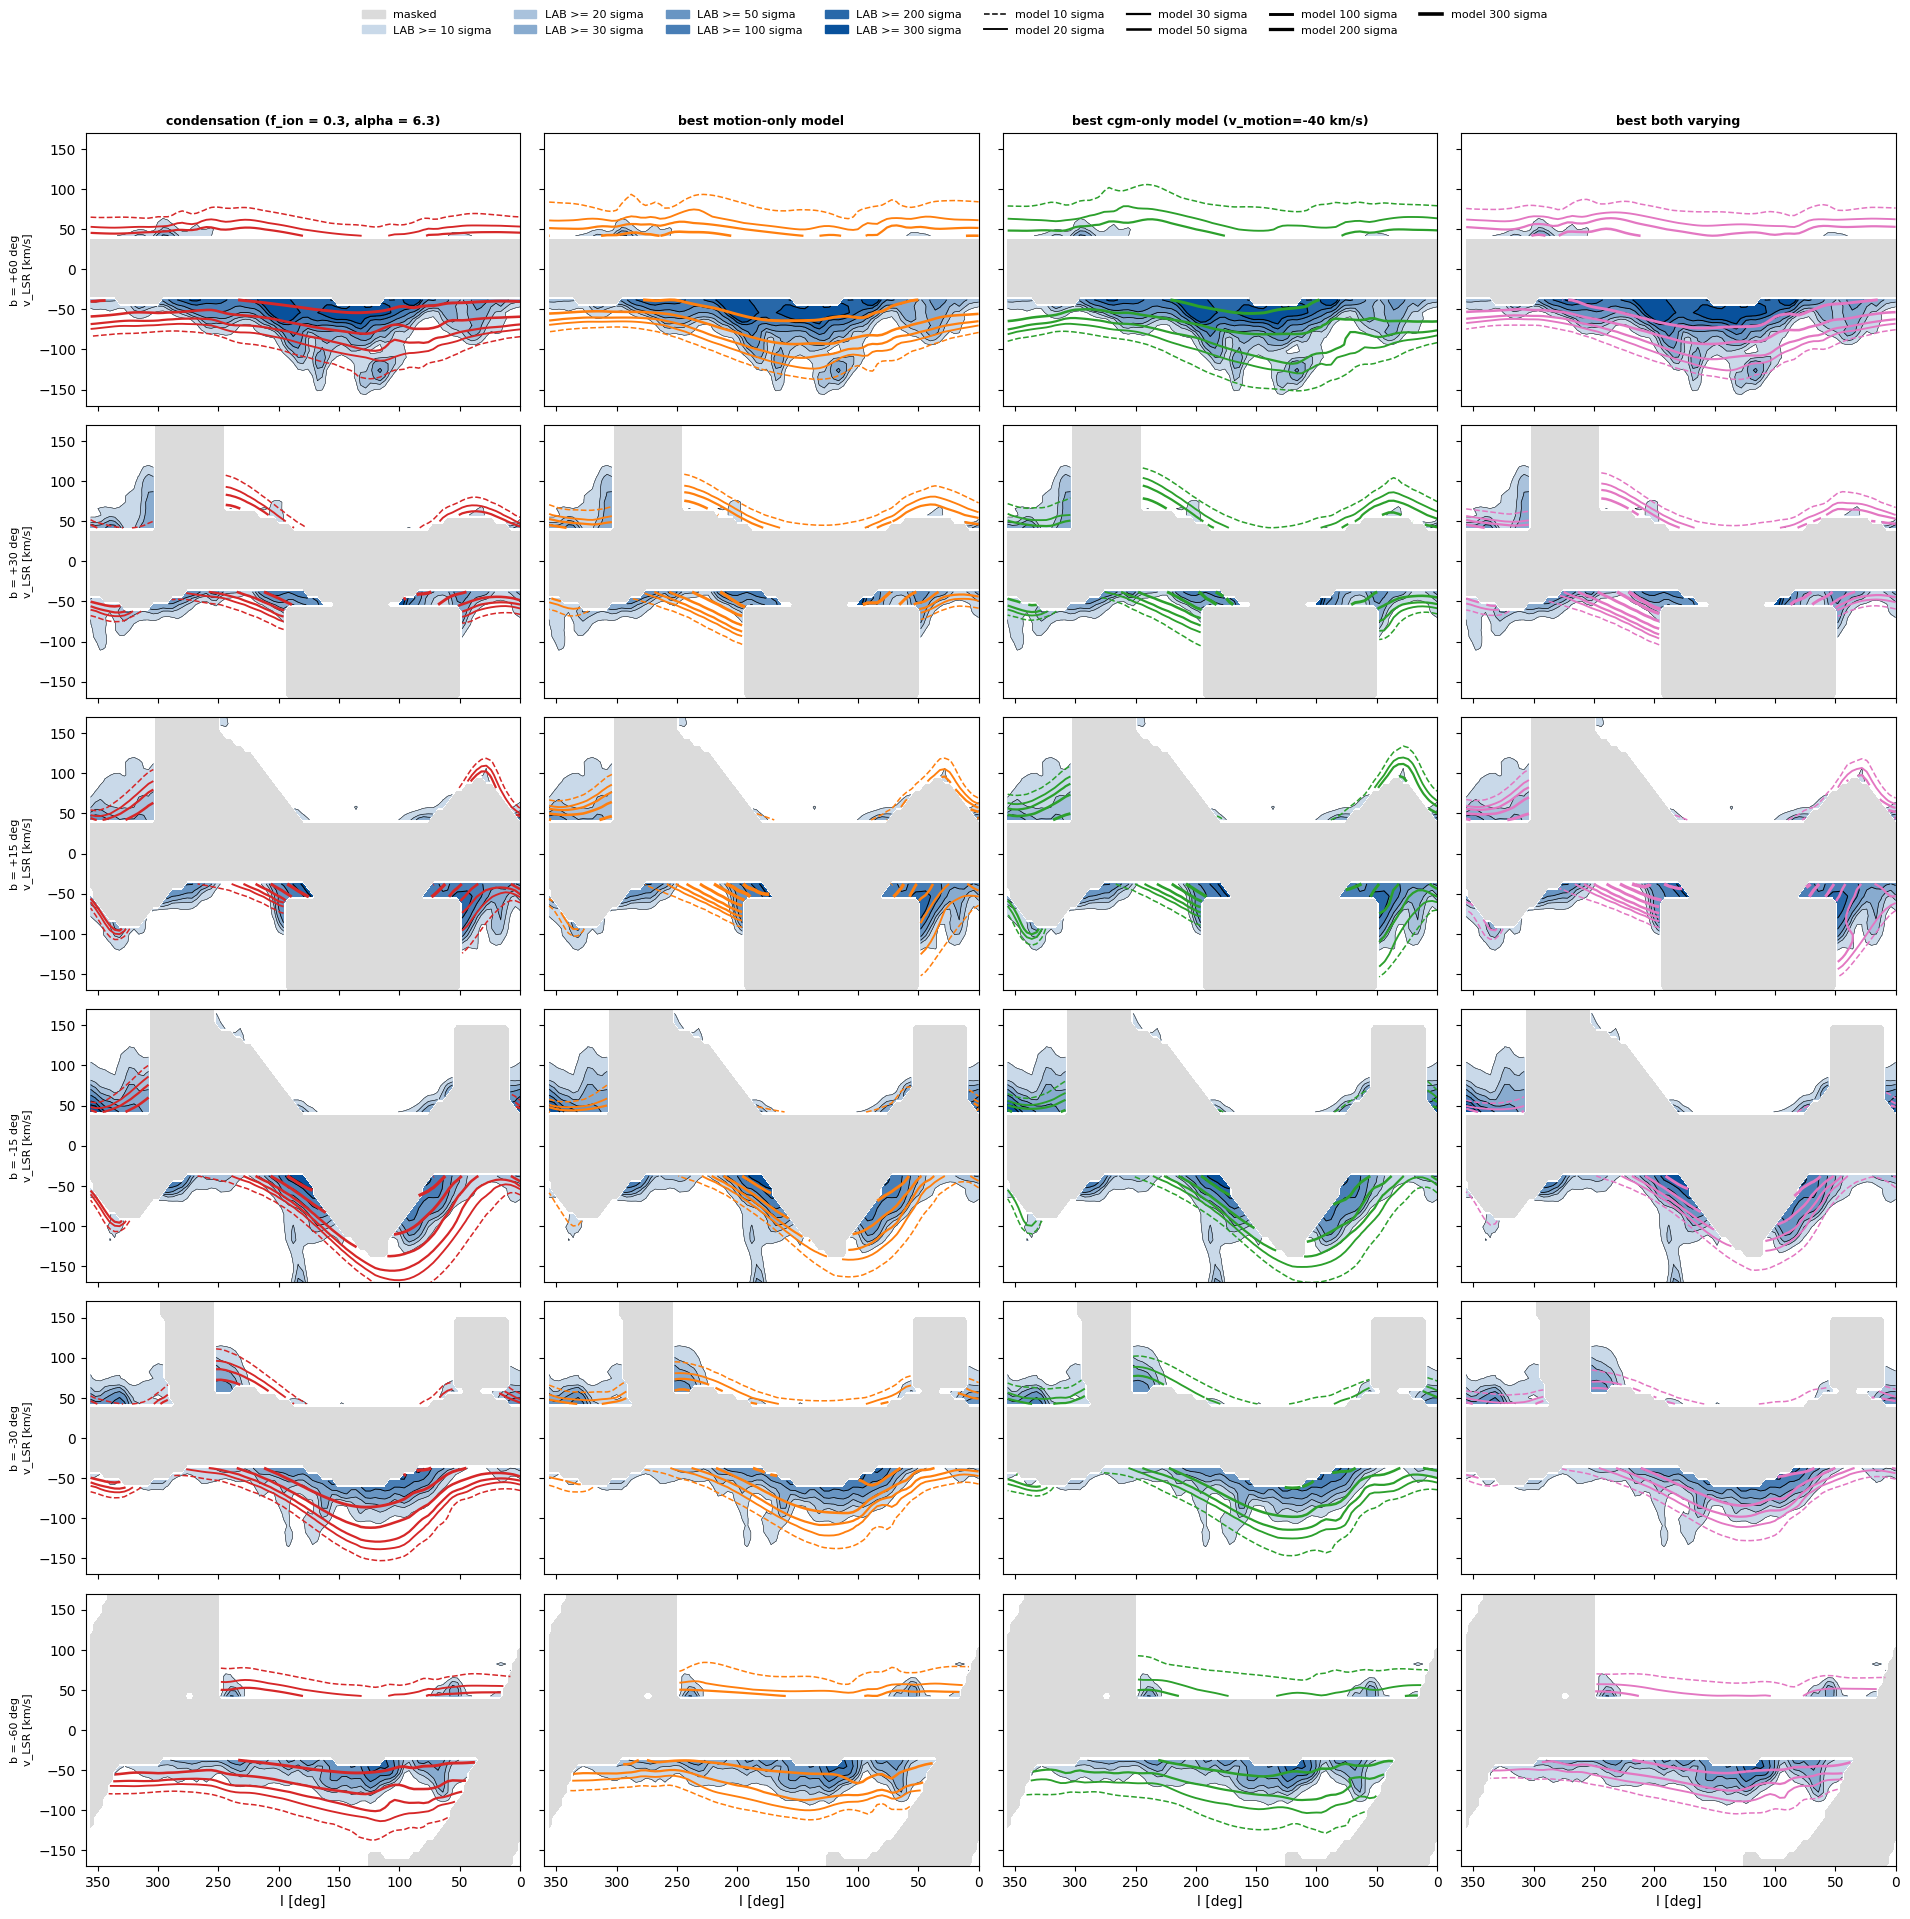

In [ ]:
sc = lambda n: cmp.scaled(MODS[n], RES[n]["scale"])
models = [(sc(names_M[6]), "condensation (f_ion = 0.3, alpha = 6.3)"),
          (sc(asym_models[0]), "best motion-only model"),
          (sc(asym_models[1]), "best cgm-only model (v_motion=-40 km/s)"),
          (sc(asym_models[2]), "best both varying")]

conf = dict(colors=("C3", "C1", "C2", "C6"), ks=(10, 20, 30, 50, 100, 200, 300))

plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60), **conf)
plt.savefig(PLOT / "lv_sigma_lab.png", dpi=150)
plt.show()

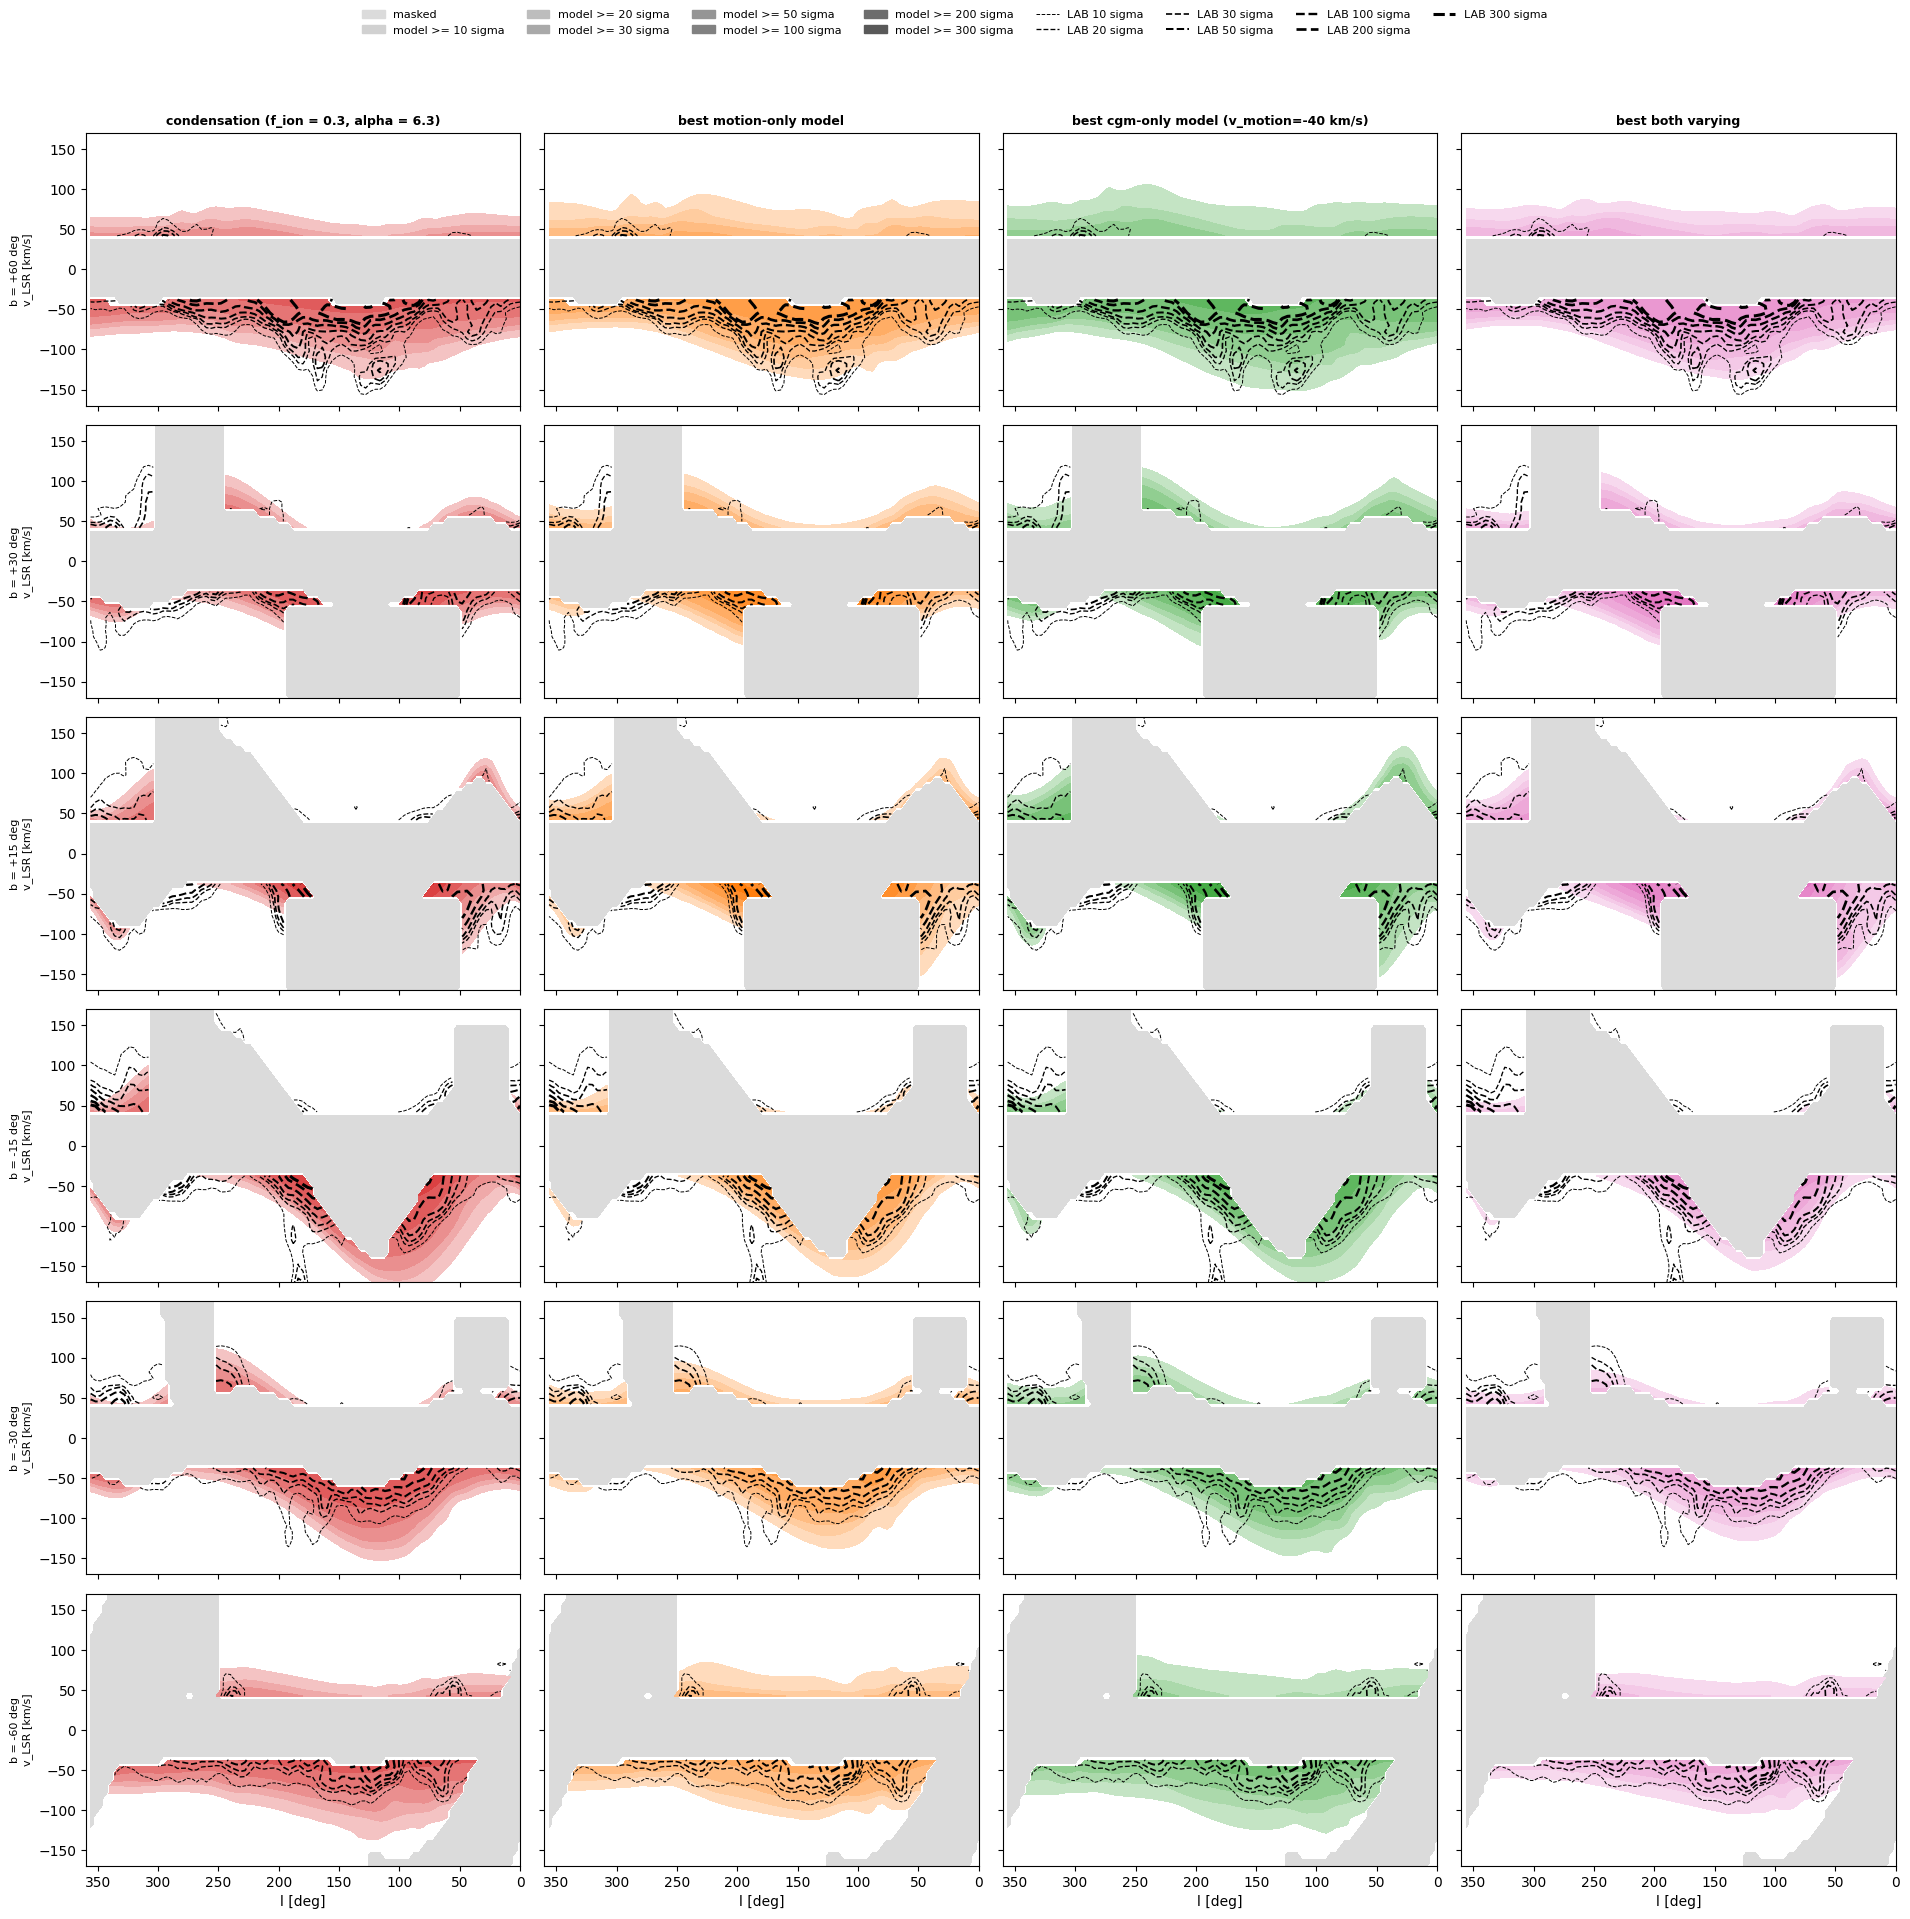

In [6]:
plot_lv_sigma(cmp.lab_cmp, models, SIGMA, b_targets=(60, 30, 15, -15, -30, -60), style="model", **conf)
plt.savefig(PLOT / "lv_sigma_model.png", dpi=150)
plt.show()

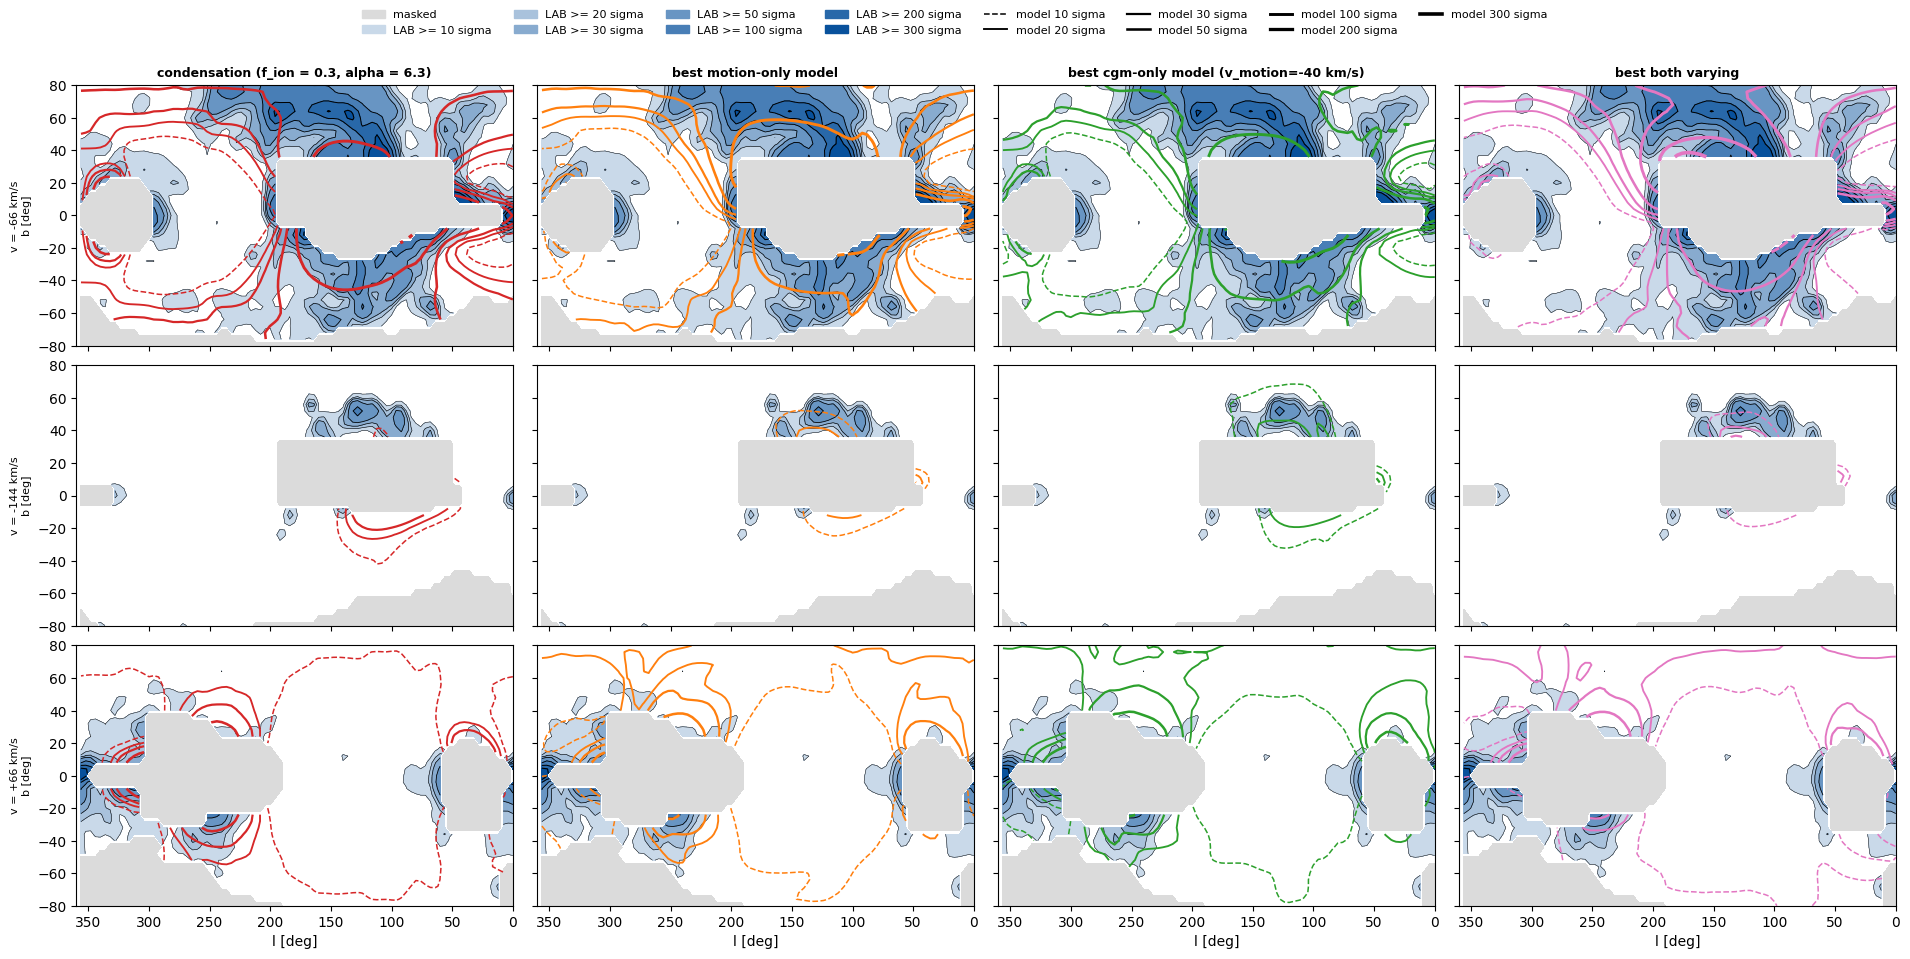

In [7]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0), **conf)
plt.savefig(PLOT / "channel_sigma_lab.png", dpi=150)
plt.show()

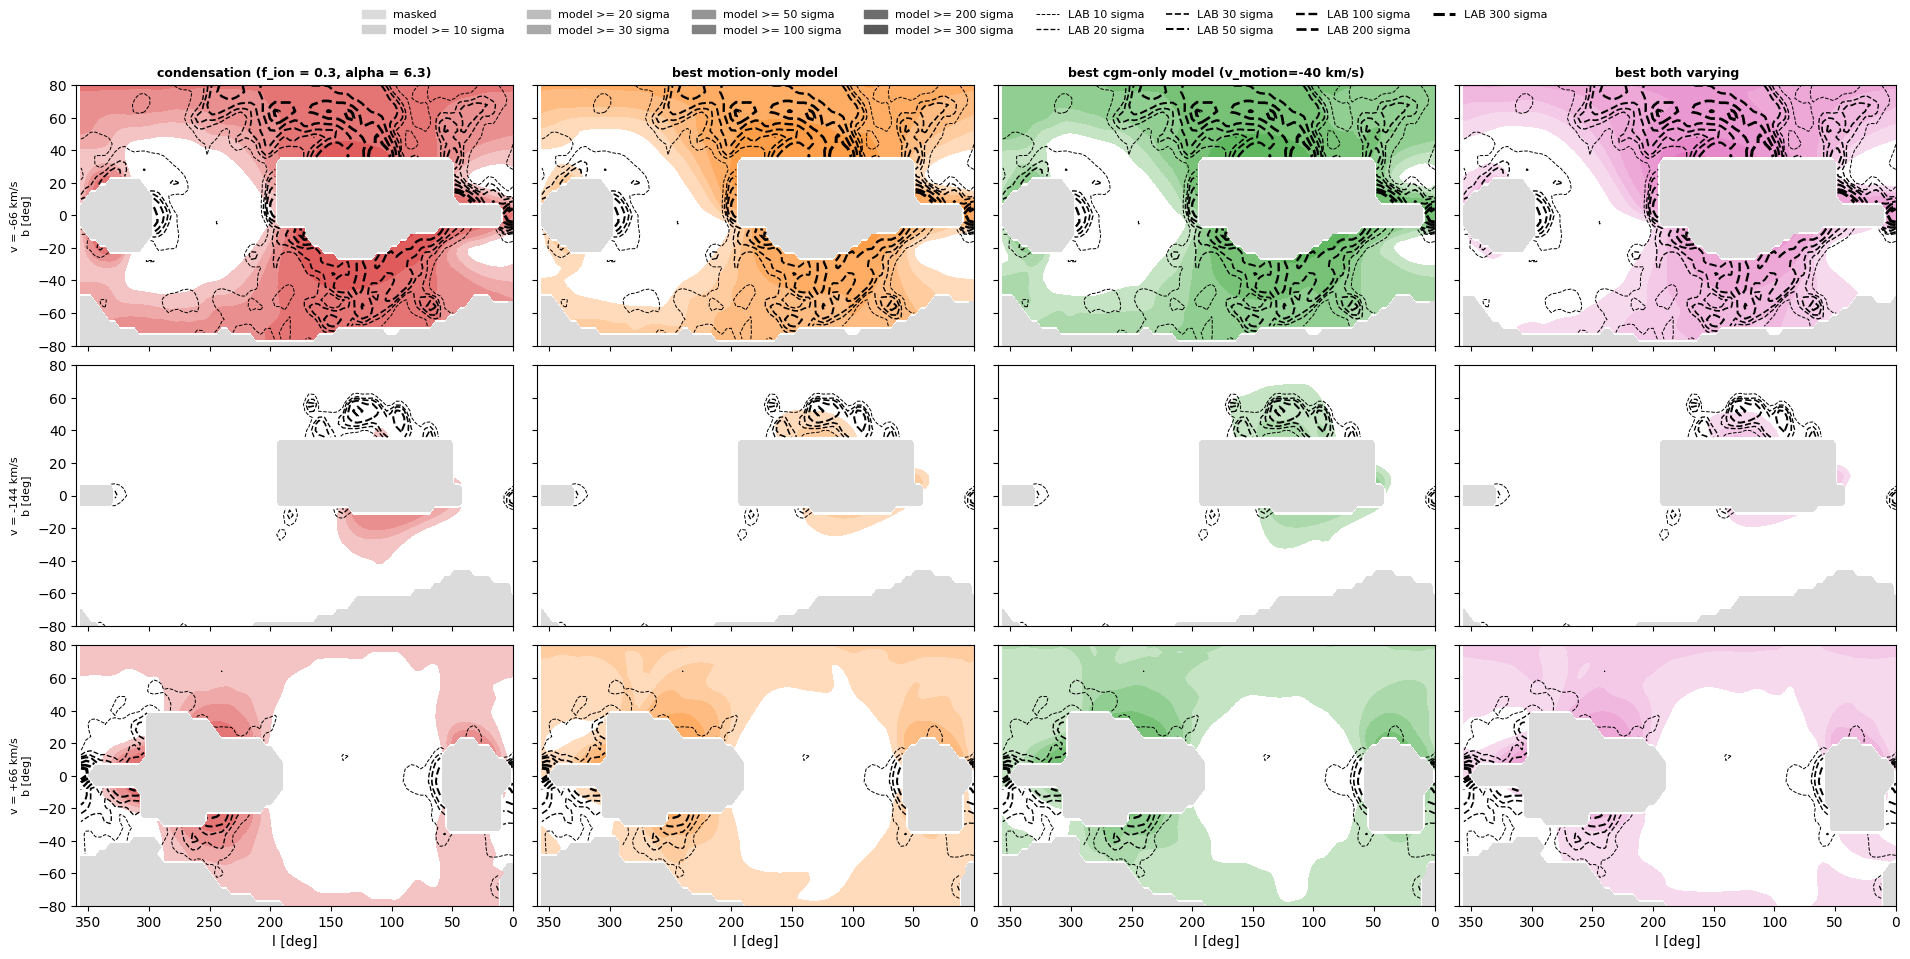

In [8]:
plot_channel_sigma(cmp.lab_cmp, models, SIGMA, v_targets=(-66.0, -144.0, 66.0), style="model", **conf)
plt.savefig(PLOT / "channel_sigma_model.png", dpi=150)
plt.show()